# Level 3 - Task: NLP Sentiment Analysis
Uses nltk (tokenize / stopwords / lemmatize), TextBlob (sentiment) and wordcloud when installed
(`pip install nltk textblob wordcloud`). If a library or its data is missing, a built-in fallback
is used so the notebook still runs end to end. The tools actually used are printed below.

In [1]:
import re, os
from collections import Counter
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

os.makedirs("plots", exist_ok=True)
TOOLS = {}

try:
    import nltk
    from nltk.corpus import stopwords
    from nltk.tokenize import word_tokenize
    from nltk.stem import WordNetLemmatizer
    for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
        nltk.download(pkg, quiet=True)
    STOP = set(stopwords.words("english")); LEM = WordNetLemmatizer()
    tokenize = lambda t: word_tokenize(t)
    lemmatize = LEM.lemmatize
    TOOLS["preprocessing"] = "nltk"
except Exception:
    STOP = set("a an the and or but if is are was were be been am i me my we you he she it its they them this that these those "
               "of to in on at for with by from as so very just not no nor too than then also into about over after it's "
               "had has have do does did will would can could should".split())
    tokenize = lambda t: re.findall(r"[a-z']+", t)
    lemmatize = lambda w: w[:-1] if w.endswith("s") and not w.endswith("ss") and len(w) > 3 else w
    TOOLS["preprocessing"] = "built-in fallback (regex tokenizer, stopword list, simple lemmatizer)"

POS = set("love excellent fantastic great amazing happy recommend wonderful reliable beautifully perfectly perfect good best "
          "exceeded fast awesome nice".split())
NEG = set("terrible awful worst poor defective hate waste disappointing disappointed useless broke damaged late overpriced "
          "bad broken horrible".split())
try:
    from textblob import TextBlob
    polarity = lambda t: TextBlob(t).sentiment.polarity
    TOOLS["sentiment"] = "TextBlob"
except Exception:
    def polarity(t):
        w = re.findall(r"[a-z']+", t.lower())
        s = sum(x in POS for x in w) - sum(x in NEG for x in w)
        return max(-1, min(1, s / 3))
    TOOLS["sentiment"] = "built-in word-list scorer"
print("Tools used:", TOOLS)

Tools used: {'preprocessing': 'built-in fallback (regex tokenizer, stopword list, simple lemmatizer)', 'sentiment': 'built-in word-list scorer'}


## 1. Load data

In [2]:
df = pd.read_csv("reviews.csv")      # replace with your own file; keep a 'review' column
print(df.shape); print(df.head())

(100, 2)
                                              review true_label
0  Wonderful experience, the phone is reliable an...   positive
1             It is an average camera, does the job.    neutral
2  Very poor service and a defective headphones. ...   negative
3  Worst purchase ever. The camera is useless and...   negative
4  Decent headphones for the price, neither good ...    neutral


## 2. Preprocess: tokenize, remove stopwords, lemmatize

In [3]:
def preprocess(text):
    toks = tokenize(re.sub(r"[^a-z\s']", " ", str(text).lower()))
    return [lemmatize(t) for t in toks if t not in STOP and len(t) > 2]

df["tokens"] = df["review"].apply(preprocess)
df["clean"] = df["tokens"].apply(" ".join)
print(df[["review", "clean"]].head())

                                              review                                              clean
0  Wonderful experience, the phone is reliable an...  wonderful experience phone reliable beautifull...
1             It is an average camera, does the job.                                 average camera job
2  Very poor service and a defective headphones. ...  poor service defective headphone hate complete...
3  Worst purchase ever. The camera is useless and...  worst purchase ever camera useless totally dis...
4  Decent headphones for the price, neither good ...            decent headphone price neither good bad


## 3. Sentiment classification (polarity > 0.05 positive, < -0.05 negative, else neutral)

In [4]:
df["polarity"] = df["review"].apply(polarity)
df["sentiment"] = pd.cut(df["polarity"], [-1.01, -0.05, 0.05, 1.01],
                         labels=["negative", "neutral", "positive"]).astype(str)
print(df["sentiment"].value_counts())
if "true_label" in df:
    print("\nAgreement with demo labels:", round((df["sentiment"] == df["true_label"]).mean(), 3))
df.drop(columns="tokens").to_csv("sentiment_results.csv", index=False)

sentiment
positive    40
negative    40
neutral     20
Name: count, dtype: int64

Agreement with demo labels: 1.0


## 4. Visualizations

Top words: [('quality', 19), ('arrived', 19), ('service', 17), ('camera', 16), ('laptop', 16), ('phone', 15), ('happy', 13), ('highly', 13), ('recommend', 13), ('exceeded', 13)]


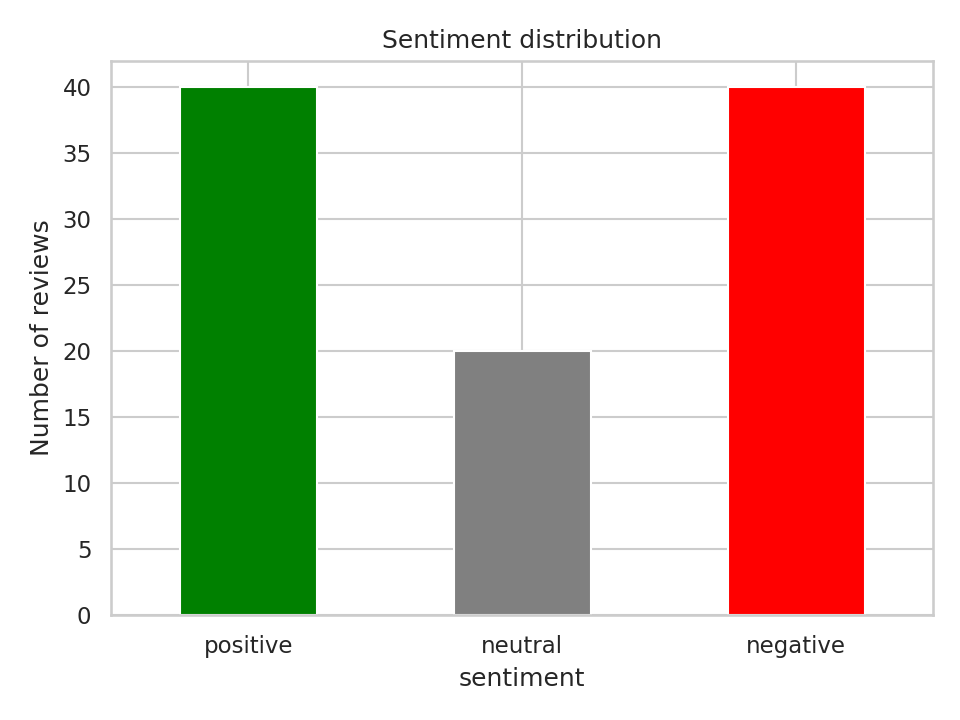

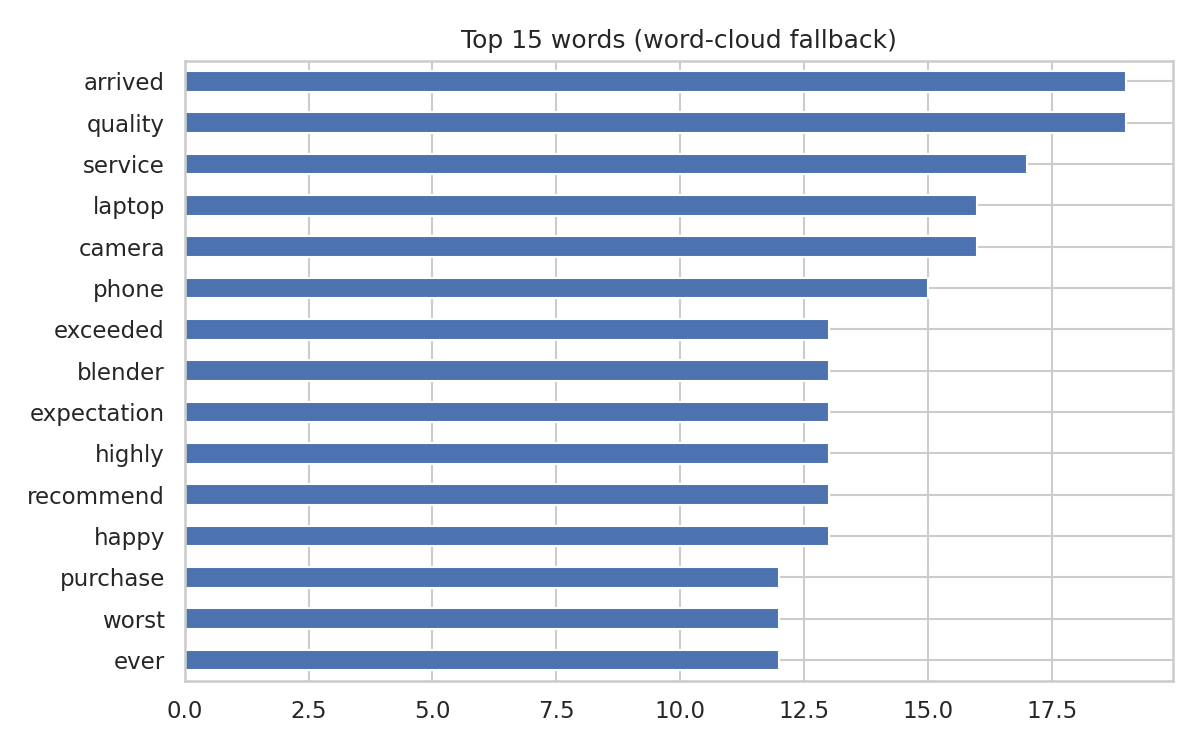

In [5]:
order = ["positive", "neutral", "negative"]
df["sentiment"].value_counts().reindex(order).fillna(0).plot(
    kind="bar", color=["green", "grey", "red"], rot=0, title="Sentiment distribution")
plt.ylabel("Number of reviews"); plt.tight_layout()
plt.savefig("plots/sentiment_distribution.png", dpi=150); plt.close()

freq = Counter(w for t in df["tokens"] for w in t)
try:
    from wordcloud import WordCloud
    wc = WordCloud(width=900, height=450, background_color="white").generate_from_frequencies(freq)
    plt.figure(figsize=(10, 5)); plt.imshow(wc); plt.axis("off"); plt.title("Word cloud")
    plt.savefig("plots/wordcloud.png", dpi=150, bbox_inches="tight"); plt.close()
except Exception:
    top = pd.Series(dict(freq.most_common(15))).sort_values()
    top.plot(kind="barh", figsize=(8, 5), title="Top 15 words (word-cloud fallback)")
    plt.tight_layout(); plt.savefig("plots/word_frequencies.png", dpi=150); plt.close()
print("Top words:", freq.most_common(10))